In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pynwb import NWBFile, NWBHDF5IO
from scipy import signal
from scipy.io import savemat
import h5py
from pathlib import Path

pd.set_option('display.max_rows', None)

Define useful functions

In [2]:
def subsample_lfp(lfp_raw, selected_channels, subsampling_factor):
    """
    Subsamples LFP data

    Parameters:
    ----------

    lfp_raw : numpy.ndarray
        2D array of LFP values (time x channels)
    selected_channels : numpy.ndarray
        Indices of channels to select (spatial subsampling)
    downsampling_factor : int
        Factor by which to subsample in time

    Returns:

    lfp_subsampled : numpy.ndarray
        New 2D array of LFP values

    """

    num_samples = len(lfp_raw[::subsampling_factor, 0])
    num_channels = selected_channels.size
    lfp_subsampled = np.zeros((num_samples, num_channels), dtype='int16')

    for new_ch, old_ch in enumerate(selected_channels):
        tmp = signal.decimate(
            lfp_raw[:, old_ch], subsampling_factor, ftype='iir', zero_phase=True
        )
        assert (len(tmp) == num_samples)
        lfp_subsampled[:, new_ch] = tmp.astype('int16')

    return lfp_subsampled

Set path to downloaded NWB files

In [3]:
NWBfiles_dir = Path(r"E:\TempletonNWB\data")
# NWBfiles_dir = Path(r"C:\Users\jhmis\Downloads\Irene-Jonathan")

Get a dataframe of some session metadata

In [4]:
subject_session_list = []
for filei in NWBfiles_dir.iterdir():
    if 'nwb' in str(filei):
        print(filei)
        io = NWBHDF5IO(filei, mode="r")
        try:
            nwbfile = io.read()
            if 'ketanserin' in nwbfile.pharmacology:
                session_drug = 'ketanserin'
            elif 'psilocybin' in nwbfile.pharmacology:
                session_drug = 'psilocybin'
            elif 'saline' in nwbfile.pharmacology:
                session_drug = 'saline'
            elif 'isoflurane' in nwbfile.pharmacology:
                session_drug = 'isoflurane'
            elif 'urethane' in nwbfile.pharmacology:
                session_drug = 'urethane'
            subject_session_list.append([
                nwbfile.subject.subject_id, nwbfile.session_id, nwbfile.subject.sex, filei, session_drug,
                np.any([True if 'EEG' in x else False for x in nwbfile.electrode_groups.keys()]),
                np.any([True if 'probe' in x else False for x in nwbfile.electrode_groups.keys()]),
            ])
            io.close
        except TypeError:
            print(' Missing version in file??')
subject_df = pd.DataFrame(subject_session_list, columns=['subject', 'session_id', 'sex', 'file_loc', 'drug', 'has_EEG', 'has_NPX'])

E:\TempletonNWB\data\631037-20221206-v001.nwb
E:\TempletonNWB\data\631037-20221207-v001.nwb
E:\TempletonNWB\data\654182-20221201-v001.nwb
E:\TempletonNWB\data\654182-20221202-v001.nwb
E:\TempletonNWB\data\655955-20221213-v001.nwb
E:\TempletonNWB\data\655955-20221214-v001.nwb
E:\TempletonNWB\data\655956-20221215-v001.nwb
E:\TempletonNWB\data\655956-20221216-v001.nwb
E:\TempletonNWB\data\657903-20230113-v001.nwb
E:\TempletonNWB\data\666193-20230215-v001.nwb
E:\TempletonNWB\data\666193-20230216-v001.nwb
E:\TempletonNWB\data\666193-20230217-v001.nwb
E:\TempletonNWB\data\666194-20230222-v001.nwb
E:\TempletonNWB\data\666194-20230223-v001.nwb
E:\TempletonNWB\data\666194-20230224-v001.nwb
E:\TempletonNWB\data\666196-20230315-v001.nwb
E:\TempletonNWB\data\666196-20230316-v001.nwb
E:\TempletonNWB\data\669117-20230329-v001.nwb
E:\TempletonNWB\data\669117-20230330-v001.nwb
E:\TempletonNWB\data\669117-20230331-v001.nwb
E:\TempletonNWB\data\669118-20230323-v001.nwb
E:\TempletonNWB\data\669118-202303

In [25]:
subject_df

,subject,session_id,sex,file_loc,drug,has_EEG,has_NPX
0,631037,20221206,M,E:\TempletonNWB\data\631037-20221206-v001.nwb,saline,True,True
1,631037,20221207,M,E:\TempletonNWB\data\631037-20221207-v001.nwb,urethane,True,True
2,654182,20221201,F,E:\TempletonNWB\data\654182-20221201-v001.nwb,saline,True,True
3,654182,20221202,F,E:\TempletonNWB\data\654182-20221202-v001.nwb,urethane,True,True
4,655955,20221213,F,E:\TempletonNWB\data\655955-20221213-v001.nwb,saline,True,True
5,655955,20221214,F,E:\TempletonNWB\data\655955-20221214-v001.nwb,urethane,True,True
6,655956,20221215,M,E:\TempletonNWB\data\655956-20221215-v001.nwb,saline,True,True
7,655956,20221216,M,E:\TempletonNWB\data\655956-20221216-v001.nwb,urethane,True,True
8,657903,20230113,M,E:\TempletonNWB\data\657903-20230113-v001.nwb,psilocybin,True,True
9,666193,20230215,M,E:\TempletonNWB\data\666193-20230215-v001.nwb,saline,False,True


In [24]:
#startingfiles = [1,3,5,9,16,17,18,19,21,22,24,26,29,31,36,38,40,41,44,46,50,56,61,64,66,70,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90]
#startingfiles = [x - 1 for x in startingfiles]
#badFile = [3,5,6,16,20,23,24,26,28,29,37,41,45]
#badFile = [x-1 for x in badFile]
#
#for i in sorted(badFile, reverse=True):
#    del startingfiles[i]

# startingfiles = [0,1,2,3]
startingfiles = [68]

files2Save = startingfiles

path = r"C:\neuropixel_anesthesia"

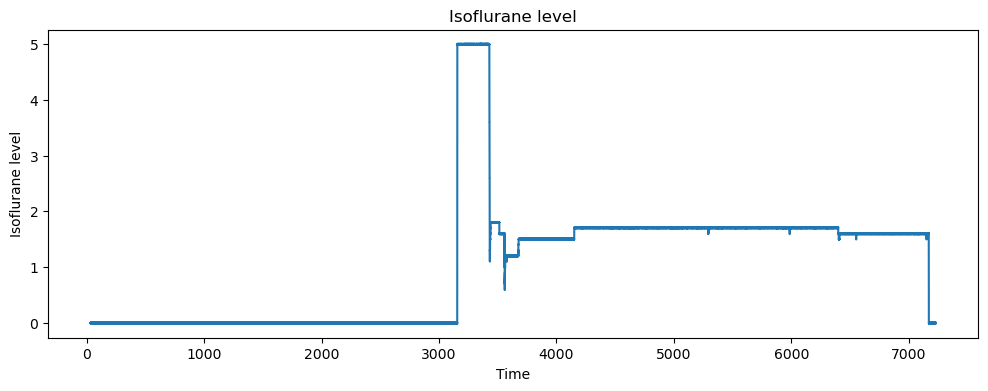

In [25]:
subjectInd = 68
io = NWBHDF5IO(
    subject_df.iloc[subjectind].file_loc,
    mode="r"
)

nwbfile = io.read()

iso_es = nwbfile.acquisition["isoflurane_level"]

iso_ts = (
            np.arange(len(iso_level)) /
            iso_es.rate
        ) + iso_es.starting_time

iso_level = iso_es.data[:]

plt.figure(figsize=(12, 4))
plt.plot(iso_ts,iso_level)
plt.xlabel("Time")
plt.ylabel("Isoflurane level")
plt.title("Isoflurane level")
plt.show()

In [26]:
import numpy as np
import h5py

from pathlib import Path
from scipy import signal
from scipy.io import savemat
from pynwb import NWBHDF5IO


# ------------------------------------------------------------
# Time window to save
#
# These are ABSOLUTE NWB times.
# Everything saved below is shifted so:
#
#       common_start = 0 seconds
#
# ------------------------------------------------------------
start_seconds = 3150
end_seconds = 4600

LFP_new_sample_rate = 500


for fileLoop in files2Save:

    subjectind = fileLoop

    io = NWBHDF5IO(
        subject_df.iloc[subjectind].file_loc,
        mode="r"
    )

    try:

        nwbfile = io.read()


        # ============================================================
        # LOAD STREAM INFORMATION AND FIND COMMON START TIME
        # ============================================================

        stream_start_times = []


        # ------------------------------------------------------------
        # Running
        # ------------------------------------------------------------

        running_es = nwbfile.processing[
            "behavior"
        ]["BehavioralTimeSeries"]["running_speed"]

        running_speed = np.asarray(
            running_es.data[:]
        )

        # Handle explicit timestamps or regular sampling
        if running_es.timestamps is not None:

            running_ts = np.asarray(
                running_es.timestamps[:]
            )

        else:

            running_ts = (
                np.arange(len(running_speed)) /
                running_es.rate
            ) + running_es.starting_time

        if len(running_ts) > 0:

            stream_start_times.append(
                running_ts[0]
            )


        # ------------------------------------------------------------
        # Pupil
        # ------------------------------------------------------------

        pupil_es = None
        pupil_width = None
        pupil_ts = None

        try:

            pupil_es = nwbfile.processing[
                "behavior"
            ]["PupilTracking"]["pupil_width"]

            pupil_width = np.asarray(
                pupil_es.data[:]
            )

            if pupil_es.timestamps is not None:

                pupil_ts = np.asarray(
                    pupil_es.timestamps[:]
                )

            else:

                pupil_ts = (
                    np.arange(len(pupil_width)) /
                    pupil_es.rate
                ) + pupil_es.starting_time

            if len(pupil_ts) > 0:

                stream_start_times.append(
                    pupil_ts[0]
                )

        except Exception:

            print(
                "This session does not have pupil tracking."
            )


        # ------------------------------------------------------------
        # Isoflurane
        # ------------------------------------------------------------

        iso_es = None
        iso_level = None
        iso_ts = None

        try:

            iso_es = nwbfile.acquisition[
                "isoflurane_level"
            ]

            iso_level = np.asarray(
                iso_es.data[:]
            )

            if iso_es.timestamps is not None:

                iso_ts = np.asarray(
                    iso_es.timestamps[:]
                )

            else:

                iso_ts = (
                    np.arange(len(iso_level)) /
                    iso_es.rate
                ) + iso_es.starting_time

            if len(iso_ts) > 0:

                stream_start_times.append(
                    iso_ts[0]
                )

        except Exception:

            print(
                "This session does not have isoflurane level."
            )


        # ------------------------------------------------------------
        # LFP streams
        # ------------------------------------------------------------

        list_of_NPXprobes = [
            x
            for x in nwbfile.electrode_groups.keys()
            if "probe" in x
        ]

        LFP_streams = {}

        for testprobe in list_of_NPXprobes:

            es = nwbfile.acquisition[
                "LFP"
            ]["ElectricalSeries" + testprobe]

            timestamps = np.asarray(
                es.timestamps[:]
            )

            LFP_streams[testprobe] = {
                "es": es,
                "timestamps": timestamps
            }

            if len(timestamps) > 0:

                stream_start_times.append(
                    timestamps[0]
                )


        # ------------------------------------------------------------
        # EEG
        # ------------------------------------------------------------

        EEG_es = None
        EEG_ts = None

        try:

            EEG_es = nwbfile.acquisition[
                "ElectricalSeriesEEG"
            ]

            if EEG_es.timestamps is not None:

                EEG_ts = np.asarray(
                    EEG_es.timestamps[:]
                )

            else:

                n_eeg_samples = (
                    EEG_es.data.shape[0]
                )

                EEG_ts = (
                    np.arange(n_eeg_samples) /
                    EEG_es.rate
                ) + EEG_es.starting_time

            if len(EEG_ts) > 0:

                stream_start_times.append(
                    EEG_ts[0]
                )

        except Exception:

            print(
                "This session does not have EEG."
            )


        # ============================================================
        # DETERMINE FINAL COMMON START
        # ============================================================

        if len(stream_start_times) == 0:

            raise RuntimeError(
                f"No continuous streams found "
                f"for subject {subjectind}"
            )

        latest_stream_start = np.max(
            stream_start_times
        )

        # Respect:
        #   1. requested anesthesia start time
        #   2. latest actual stream start
        common_start = max(
            start_seconds,
            latest_stream_start
        )

        if common_start >= end_seconds:

            raise RuntimeError(
                f"No common data interval for "
                f"subject {subjectind}: "
                f"common_start={common_start}, "
                f"end_seconds={end_seconds}"
            )

        aligned_end = (
            end_seconds - common_start
        )

        print(
            f"\nSubject {subjectind}"
        )

        print(
            f"Absolute common start: "
            f"{common_start:.6f} s"
        )

        print(
            f"Aligned saved interval: "
            f"0 to {aligned_end:.6f} s"
        )


        # ============================================================
        # RUNNING
        # ============================================================

        start_idx = np.searchsorted(
            running_ts,
            common_start,
            side="left"
        )

        end_idx = np.searchsorted(
            running_ts,
            end_seconds,
            side="left"
        )

        running_save = np.asarray(
            running_speed[
                start_idx:end_idx
            ],
            dtype=np.float32
        )

        # Align timestamps to common_start = 0
        running_ts_save = np.asarray(
            running_ts[
                start_idx:end_idx
            ] - common_start,
            dtype=np.float32
        )

        h5_out = (
            Path(path) /
            f"running_{subjectind}.h5"
        )

        with h5py.File(
            h5_out,
            "w"
        ) as f:

            f.create_dataset(
                "runningSpeed",
                data=running_save,
                compression="gzip"
            )

            f.create_dataset(
                "runningTS",
                data=running_ts_save,
                compression="gzip"
            )

            f.attrs[
                "commonStart"
            ] = common_start

            f.attrs[
                "alignedEnd"
            ] = aligned_end


        # ============================================================
        # PUPIL
        # ============================================================

        if pupil_ts is not None:

            start_idx = np.searchsorted(
                pupil_ts,
                common_start,
                side="left"
            )

            end_idx = np.searchsorted(
                pupil_ts,
                end_seconds,
                side="left"
            )

            pupil_save = np.asarray(
                pupil_width[
                    start_idx:end_idx
                ],
                dtype=np.float32
            )

            # Align timestamps
            pupil_ts_save = np.asarray(
                pupil_ts[
                    start_idx:end_idx
                ] - common_start,
                dtype=np.float32
            )

            h5_out = (
                Path(path) /
                f"pupil_{subjectind}.h5"
            )

            with h5py.File(
                h5_out,
                "w"
            ) as f:

                f.create_dataset(
                    "pupilSize",
                    data=pupil_save,
                    compression="gzip"
                )

                f.create_dataset(
                    "pupilTS",
                    data=pupil_ts_save,
                    compression="gzip"
                )

                f.attrs[
                    "commonStart"
                ] = common_start

                f.attrs[
                    "alignedEnd"
                ] = aligned_end


        # ============================================================
        # ISOFLURANE LEVEL
        # ============================================================

        if iso_ts is not None:

            start_idx = np.searchsorted(
                iso_ts,
                common_start,
                side="left"
            )

            end_idx = np.searchsorted(
                iso_ts,
                end_seconds,
                side="left"
            )

            iso_save = np.asarray(
                iso_level[
                    start_idx:end_idx
                ],
                dtype=np.float32
            )

            # Align timestamps
            iso_ts_save = np.asarray(
                iso_ts[
                    start_idx:end_idx
                ] - common_start,
                dtype=np.float32
            )

            h5_out = (
                Path(path) /
                f"isolevel_{subjectind}.h5"
            )

            with h5py.File(
                h5_out,
                "w"
            ) as f:

                f.create_dataset(
                    "isoLevel",
                    data=iso_save,
                    compression="gzip"
                )

                f.create_dataset(
                    "iso_TS",
                    data=iso_ts_save,
                    compression="gzip"
                )

                f.attrs[
                    "commonStart"
                ] = common_start

                f.attrs[
                    "alignedEnd"
                ] = aligned_end


        # ============================================================
        # LFP
        # ============================================================

        LFP_blocks = []
        LFP_timestamp_blocks = []

        for testprobe in list_of_NPXprobes:

            es = LFP_streams[
                testprobe
            ]["es"]

            LFP_timestamps = LFP_streams[
                testprobe
            ]["timestamps"]

            start_idx = np.searchsorted(
                LFP_timestamps,
                common_start,
                side="left"
            )

            end_idx = np.searchsorted(
                LFP_timestamps,
                end_seconds,
                side="left"
            )


            # --------------------------------------------------------
            # Sampling rate
            # --------------------------------------------------------

            LFP_sample_rate = (
                1 /
                np.mean(
                    np.diff(
                        LFP_timestamps
                    )
                )
            )

            downsample_factor = int(
                round(
                    LFP_sample_rate /
                    LFP_new_sample_rate
                )
            )

            downsample_factor = max(
                downsample_factor,
                1
            )

            num_channels = (
                es.data.shape[1]
            )

            current_ts = np.asarray(
                LFP_timestamps[
                    start_idx:end_idx
                ]
            )


            # --------------------------------------------------------
            # First channel
            # --------------------------------------------------------

            raw_data = np.asarray(
                es.data[
                    start_idx:end_idx,
                    0
                ]
            )

            if downsample_factor > 1:

                lfp0 = signal.decimate(
                    raw_data,
                    downsample_factor,
                    ftype="iir",
                    zero_phase=True
                )

            else:

                lfp0 = raw_data


            # --------------------------------------------------------
            # Corresponding timestamps
            # --------------------------------------------------------

            LFP_ts_subsampled = (
                current_ts[
                    ::downsample_factor
                ]
            )

            probe_len = min(
                len(lfp0),
                len(LFP_ts_subsampled)
            )

            lfp0 = lfp0[
                :probe_len
            ]

            LFP_ts_subsampled = (
                LFP_ts_subsampled[
                    :probe_len
                ]
            )

            lfp_subsampled = np.zeros(
                (
                    probe_len,
                    num_channels
                ),
                dtype=float
            )

            lfp_subsampled[
                :,
                0
            ] = lfp0


            # --------------------------------------------------------
            # Remaining channels
            # --------------------------------------------------------

            for chi in range(
                1,
                num_channels
            ):

                raw_data = np.asarray(
                    es.data[
                        start_idx:end_idx,
                        chi
                    ]
                )

                if downsample_factor > 1:

                    temp_lfp = signal.decimate(
                        raw_data,
                        downsample_factor,
                        ftype="iir",
                        zero_phase=True
                    )

                else:

                    temp_lfp = raw_data

                lfp_subsampled[
                    :,
                    chi
                ] = temp_lfp[
                    :probe_len
                ]


            # --------------------------------------------------------
            # Align LFP timestamps
            # --------------------------------------------------------

            LFP_ts_subsampled = (
                LFP_ts_subsampled -
                common_start
            )

            LFP_blocks.append(
                lfp_subsampled
            )

            LFP_timestamp_blocks.append(
                LFP_ts_subsampled
            )


        # ------------------------------------------------------------
        # Make all probes same length
        # ------------------------------------------------------------

        if len(LFP_blocks) > 0:

            target_len = min(
                block.shape[0]
                for block in LFP_blocks
            )

            LFP_all = np.hstack(
                [
                    block[
                        :target_len,
                        :
                    ]
                    for block in LFP_blocks
                ]
            )

            LFP_TS = (
                LFP_timestamp_blocks[
                    0
                ][
                    :target_len
                ]
            )

            LFP_save = np.asarray(
                LFP_all,
                dtype=np.float32
            )

            LFP_TS = np.asarray(
                LFP_TS,
                dtype=np.float32
            )

            h5_out = (
                Path(path) /
                f"LFP_{subjectind}.h5"
            )

            with h5py.File(
                h5_out,
                "w"
            ) as f:

                f.create_dataset(
                    "LFP_all",
                    data=LFP_save,
                    compression="gzip"
                )

                f.create_dataset(
                    "LFP_TS",
                    data=LFP_TS,
                    compression="gzip"
                )

                f.attrs[
                    "commonStart"
                ] = common_start

                f.attrs[
                    "alignedEnd"
                ] = aligned_end


        # ============================================================
        # ELECTRODE INFORMATION
        # ============================================================

        electrodes_df = (
            nwbfile.electrodes
            .to_dataframe()
        )

        group_name = (
            electrodes_df[
                "group_name"
            ].values
        )

        location = (
            electrodes_df[
                "location"
            ].values
        )

        savemat(
            Path(path) /
            f"electrode_info_{subjectind}.mat",
            {
                "group_name": group_name,
                "location": location
            }
        )


        # ============================================================
        # UNITS / SPIKES
        #
        # Clip absolute spike times to:
        #
        #     [common_start, end_seconds)
        #
        # then subtract common_start so saved spikes use:
        #
        #     t = 0 at common_start
        #
        # ============================================================

        all_units_df = (
            nwbfile.units
            .to_dataframe()
            .copy()
        )

        if "spike_times" in all_units_df.columns:

            def clip_and_align_spikes(
                spike_times
            ):

                spike_times = np.asarray(
                    spike_times,
                    dtype=float
                )

                keep = (
                    (
                        spike_times
                        >= common_start
                    )
                    &
                    (
                        spike_times
                        < end_seconds
                    )
                )

                return (
                    spike_times[keep] -
                    common_start
                )


            all_units_df[
                "spike_times"
            ] = (
                all_units_df[
                    "spike_times"
                ].apply(
                    clip_and_align_spikes
                )
            )


        # ------------------------------------------------------------
        # Spike timing sanity check
        # ------------------------------------------------------------

        if "spike_times" in all_units_df.columns:

            nonempty_spikes = [
                spikes
                for spikes
                in all_units_df[
                    "spike_times"
                ]
                if len(spikes) > 0
            ]

            if len(nonempty_spikes) > 0:

                first_saved_spike = min(
                    np.min(spikes)
                    for spikes
                    in nonempty_spikes
                )

                last_saved_spike = max(
                    np.max(spikes)
                    for spikes
                    in nonempty_spikes
                )

                print(
                    f"Aligned spike range: "
                    f"{first_saved_spike:.6f} "
                    f"to "
                    f"{last_saved_spike:.6f} s"
                )

            else:

                print(
                    "No spikes in saved interval."
                )


        savemat(
            Path(path) /
            f"spikes_info_{subjectind}.mat",
            {
                "units": all_units_df,
                "commonStart": float(
                    common_start
                ),
                "alignedEnd": float(
                    aligned_end
                )
            }
        )


        # ============================================================
        # EEG
        # ============================================================

        if EEG_ts is not None:

            start_idx = np.searchsorted(
                EEG_ts,
                common_start,
                side="left"
            )

            end_idx = np.searchsorted(
                EEG_ts,
                end_seconds,
                side="left"
            )

            EEG_sample_rate = (
                1 /
                np.mean(
                    np.diff(
                        EEG_ts
                    )
                )
            )

            EEG_downsample_factor = int(
                round(
                    EEG_sample_rate /
                    LFP_new_sample_rate
                )
            )

            EEG_downsample_factor = max(
                EEG_downsample_factor,
                1
            )

            num_channels = (
                EEG_es.data.shape[1]
            )

            current_ts = np.asarray(
                EEG_ts[
                    start_idx:end_idx
                ]
            )


            # --------------------------------------------------------
            # First EEG channel
            # --------------------------------------------------------

            raw_data = np.asarray(
                EEG_es.data[
                    start_idx:end_idx,
                    0
                ]
            )

            if EEG_downsample_factor > 1:

                EEG0 = signal.decimate(
                    raw_data,
                    EEG_downsample_factor,
                    ftype="iir",
                    zero_phase=True
                )

            else:

                EEG0 = raw_data


            # --------------------------------------------------------
            # Corresponding timestamps
            # --------------------------------------------------------

            EEG_TS_save = (
                current_ts[
                    ::EEG_downsample_factor
                ]
            )

            target_len = min(
                len(EEG0),
                len(EEG_TS_save)
            )

            EEG0 = EEG0[
                :target_len
            ]

            EEG_TS_save = (
                EEG_TS_save[
                    :target_len
                ]
            )

            EEG_all = np.zeros(
                (
                    target_len,
                    num_channels
                ),
                dtype=float
            )

            EEG_all[
                :,
                0
            ] = EEG0


            # --------------------------------------------------------
            # Remaining EEG channels
            # --------------------------------------------------------

            for chi in range(
                1,
                num_channels
            ):

                raw_data = np.asarray(
                    EEG_es.data[
                        start_idx:end_idx,
                        chi
                    ]
                )

                if EEG_downsample_factor > 1:

                    temp_EEG = signal.decimate(
                        raw_data,
                        EEG_downsample_factor,
                        ftype="iir",
                        zero_phase=True
                    )

                else:

                    temp_EEG = raw_data

                EEG_all[
                    :,
                    chi
                ] = temp_EEG[
                    :target_len
                ]


            # --------------------------------------------------------
            # Align EEG timestamps
            # --------------------------------------------------------

            EEG_TS_save = (
                EEG_TS_save -
                common_start
            )

            EEG_save = np.asarray(
                EEG_all,
                dtype=np.float32
            )

            EEG_TS_save = np.asarray(
                EEG_TS_save,
                dtype=np.float32
            )

            h5_out = (
                Path(path) /
                f"EEG_{subjectind}.h5"
            )

            with h5py.File(
                h5_out,
                "w"
            ) as f:

                f.create_dataset(
                    "EEG_all",
                    data=EEG_save,
                    compression="gzip"
                )

                f.create_dataset(
                    "EEG_TS",
                    data=EEG_TS_save,
                    compression="gzip"
                )

                f.attrs[
                    "commonStart"
                ] = common_start

                f.attrs[
                    "alignedEnd"
                ] = aligned_end


        # ============================================================
        # FINAL TIMING SUMMARY
        # ============================================================

        print(
            f"Subject {subjectind} complete."
        )

        print(
            "All saved timestamps use "
            "common_start = 0."
        )

        print(
            f"Original NWB common_start = "
            f"{common_start:.6f} s"
        )

        print(
            f"Aligned recording duration = "
            f"{aligned_end:.6f} s"
        )


    finally:

        io.close()

Subject 68: common start = 3150.000000 s
